CONNECT TO GOOGLE DRIVE TO REACH FILES UNDER A SPECIFIC FOLDER

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


IMPORTING THE LIBRARIES


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline

IMPORTING THE DATASET

In [ ]:
dataset = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/weather_classification_data.csv")

UNDERSTANDING DATA

In [ ]:
dataset.columns = dataset.columns.str.replace(' ', '') #Removing the spaces from column names

In [ ]:
print(dataset.columns) #Controll if the spaces are removed

Index(['Temperature', 'Humidity', 'WindSpeed', 'Precipitation(%)',
       'CloudCover', 'AtmosphericPressure', 'UVIndex', 'Season',
       'Visibility(km)', 'Location', 'WeatherType'],
      dtype='object')


In [ ]:
dataset.rename(columns={'Precipitation(%)': 'PrecipitationPercentage'}, inplace=True) #changing the name

In [ ]:
dataset.rename(columns={'Visibility(km)': 'VisibilityKilometer'}, inplace=True) #changing the name


In [ ]:
dataset.info() #finding the feature's type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature              13200 non-null  float64
 1   Humidity                 13200 non-null  int64  
 2   WindSpeed                13200 non-null  float64
 3   PrecipitationPercentage  13200 non-null  float64
 4   CloudCover               13200 non-null  object 
 5   AtmosphericPressure      13200 non-null  float64
 6   UVIndex                  13200 non-null  int64  
 7   Season                   13200 non-null  object 
 8   VisibilityKilometer      13200 non-null  float64
 9   Location                 13200 non-null  object 
 10  WeatherType              13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


In [ ]:
dataset.describe()

,Temperature,Humidity,WindSpeed,PrecipitationPercentage,AtmosphericPressure,UVIndex,VisibilityKilometer
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


In [ ]:
dataset.describe(include='object') #categorical features

,CloudCover,Season,Location,WeatherType
count,13200,13200,13200,13200
unique,4,4,3,4
top,overcast,Winter,inland,Rainy
freq,6090,5610,4816,3300


In [ ]:
dataset.describe(include='number') #numerical features

,Temperature,Humidity,WindSpeed,PrecipitationPercentage,AtmosphericPressure,UVIndex,VisibilityKilometer
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


In [ ]:
dataset['CloudCover'].value_counts() #for categorical variables

,count
CloudCover,
overcast,6090
partly cloudy,4560
clear,2139
cloudy,411


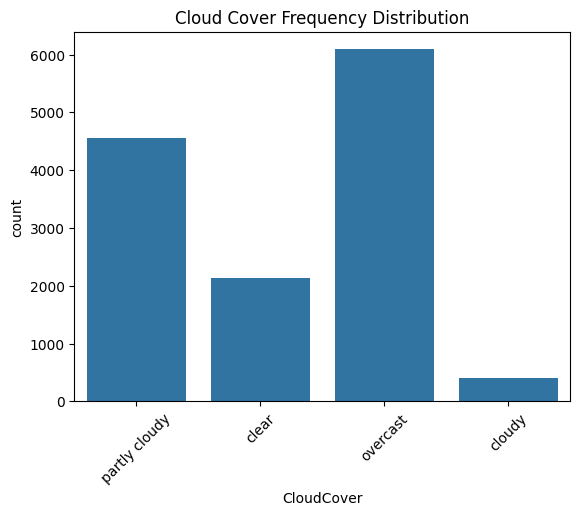

In [ ]:
sns.countplot(x=dataset['CloudCover'])
plt.title('Cloud Cover Frequency Distribution')
plt.xticks(rotation=45)
plt.show()

In [ ]:
dataset['Season'].value_counts() #for categorical variables


,count
Season,
Winter,5610
Spring,2598
Autumn,2500
Summer,2492


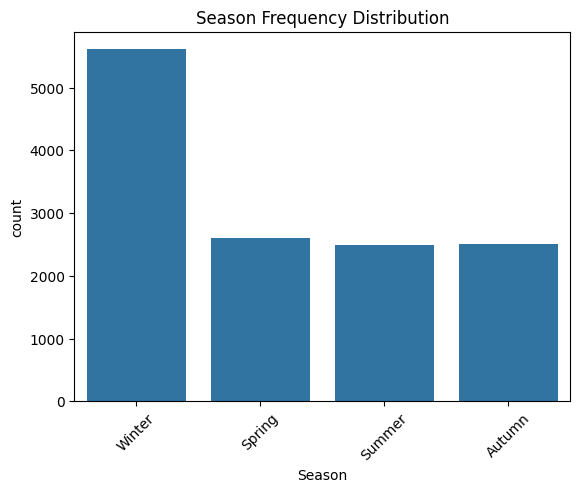

In [ ]:
sns.countplot(x=dataset['Season'])
plt.title('Season Frequency Distribution')
plt.xticks(rotation=45)
plt.show()

In [ ]:
dataset['Location'].value_counts() #for categorical variables


,count
Location,
inland,4816
mountain,4813
coastal,3571


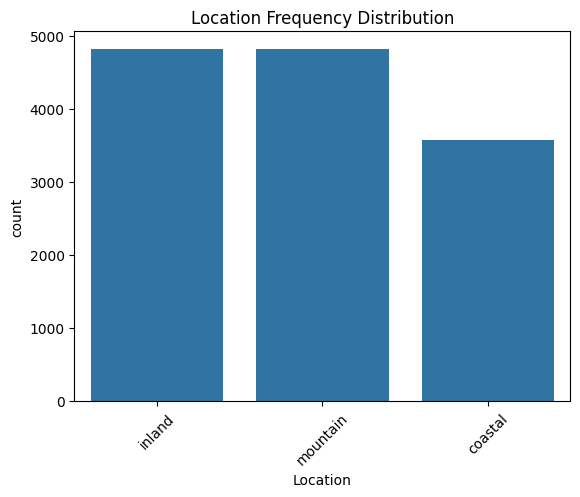

In [ ]:
sns.countplot(x=dataset['Location'])
plt.title('Location Frequency Distribution')
plt.xticks(rotation=45)
plt.show()

In [ ]:
dataset['WeatherType'].value_counts() #for categorical variables (Checking the distribution of classes)


,count
WeatherType,
Rainy,3300
Cloudy,3300
Sunny,3300
Snowy,3300


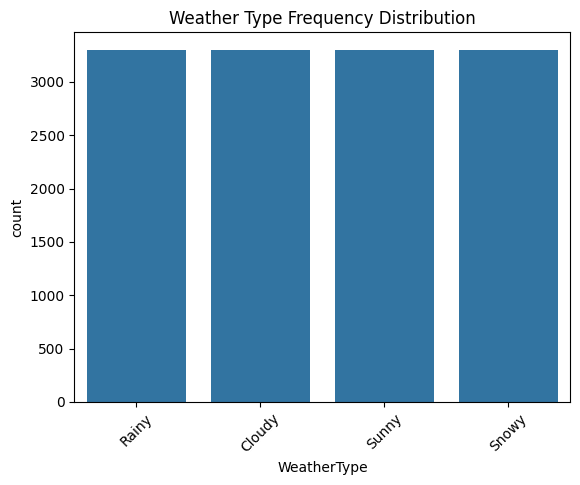

In [ ]:
sns.countplot(x=dataset['WeatherType'])
plt.title('Weather Type Frequency Distribution')
plt.xticks(rotation=45)
plt.show()

HANDLING MISSING DATA

In [ ]:
print(dataset.isnull().sum())  # Check the number of missing values in each column (There is no missing value)

Temperature                0
Humidity                   0
WindSpeed                  0
PrecipitationPercentage    0
CloudCover                 0
AtmosphericPressure        0
UVIndex                    0
Season                     0
VisibilityKilometer        0
Location                   0
WeatherType                0
dtype: int64


DISTRIBUTION ANALYSIS

<Axes: >

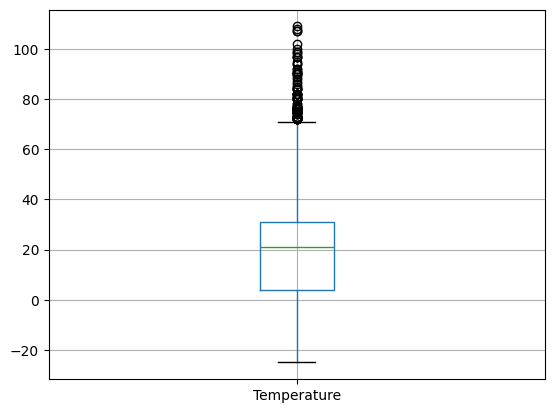

In [ ]:
dataset.boxplot(column='Temperature')

<Axes: >

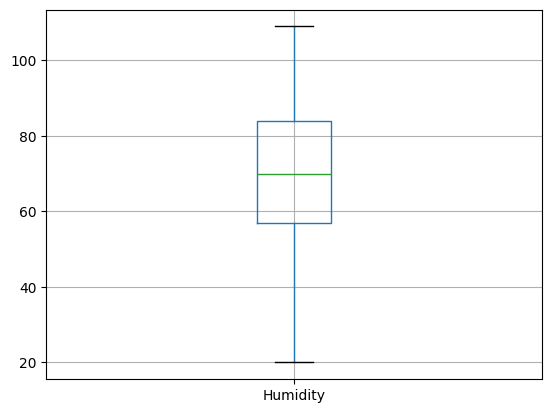

In [ ]:
dataset.boxplot(column='Humidity')

<Axes: >

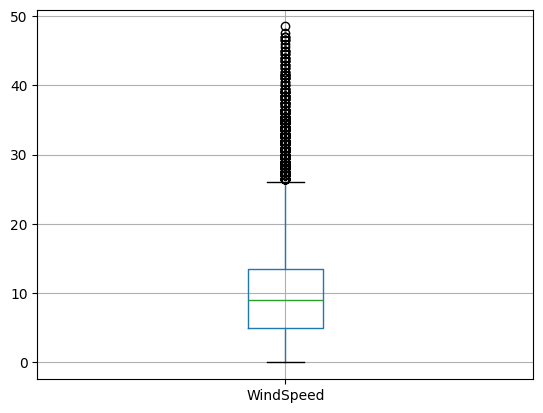

In [ ]:
dataset.boxplot(column='WindSpeed')

<Axes: >

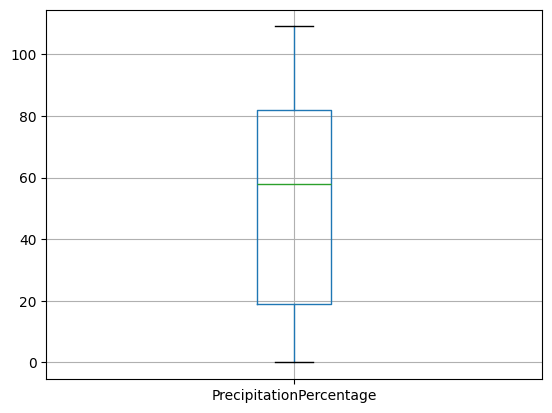

In [ ]:
dataset.boxplot(column='PrecipitationPercentage')

<Axes: >

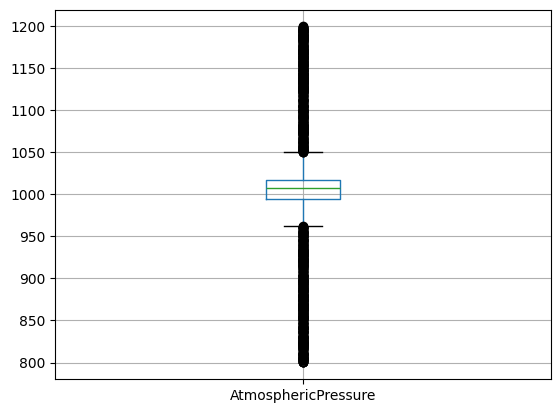

In [ ]:
dataset.boxplot(column='AtmosphericPressure')

<Axes: >

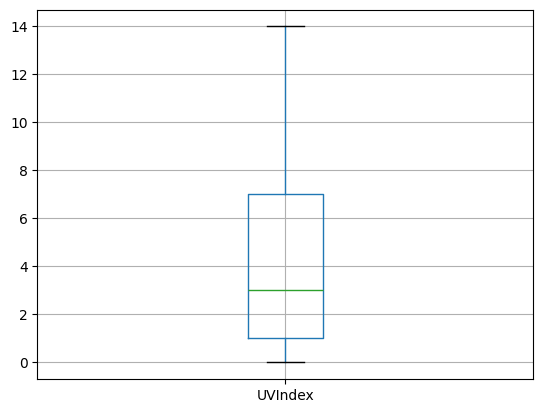

In [ ]:
dataset.boxplot(column='UVIndex')

<Axes: >

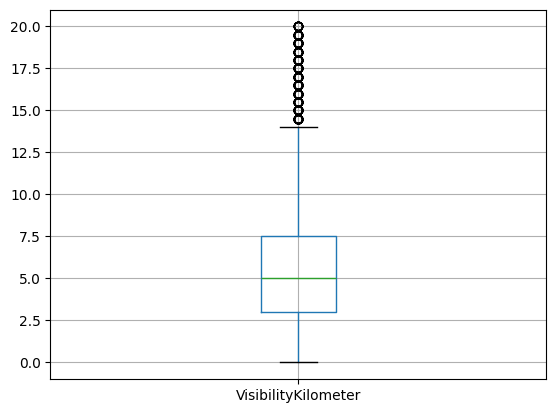

In [ ]:
dataset.boxplot(column='VisibilityKilometer')


HISTOGRAMS OF THE NUMERICAL FEATURES

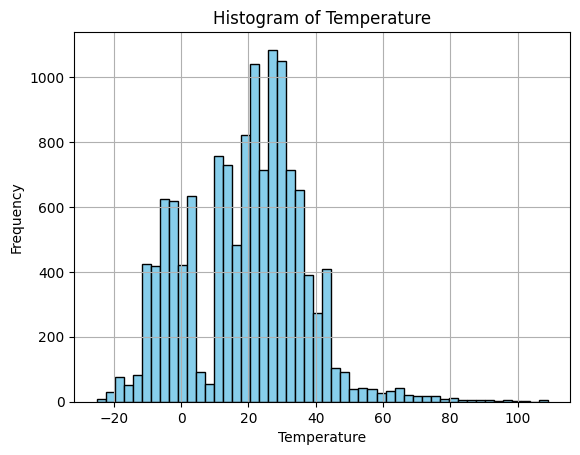

In [ ]:
dataset['Temperature'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Temperature')
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.show() #Şekil 16

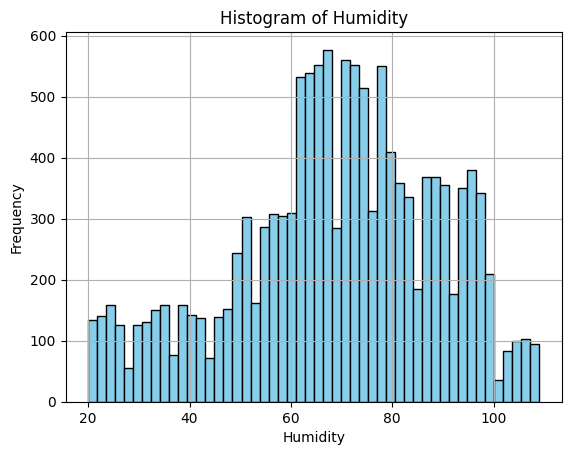

In [ ]:
dataset['Humidity'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Humidity')
plt.xlabel('Humidity')
plt.ylabel('Frequency')
plt.show() #Şekil 17

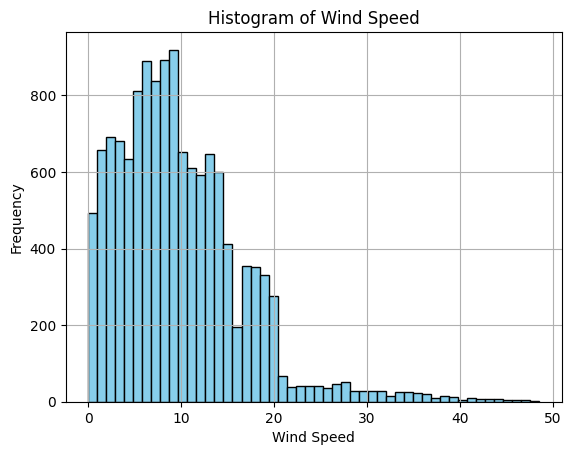

In [ ]:
dataset['WindSpeed'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Wind Speed')
plt.xlabel('Wind Speed')
plt.ylabel('Frequency')
plt.show() #Şekil 18

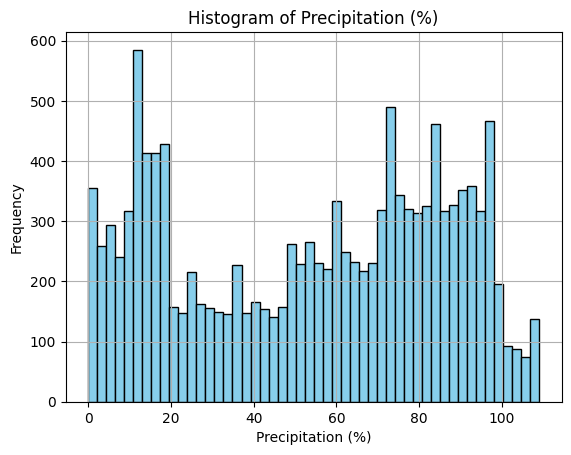

In [ ]:
dataset['PrecipitationPercentage'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Precipitation (%)')
plt.xlabel('Precipitation (%)')
plt.ylabel('Frequency')
plt.show() #Şekil 19

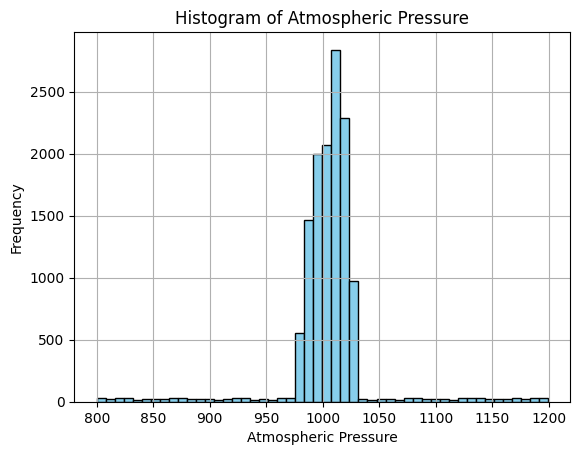

In [ ]:
dataset['AtmosphericPressure'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Atmospheric Pressure')
plt.xlabel('Atmospheric Pressure')
plt.ylabel('Frequency')
plt.show() #Şekil 20

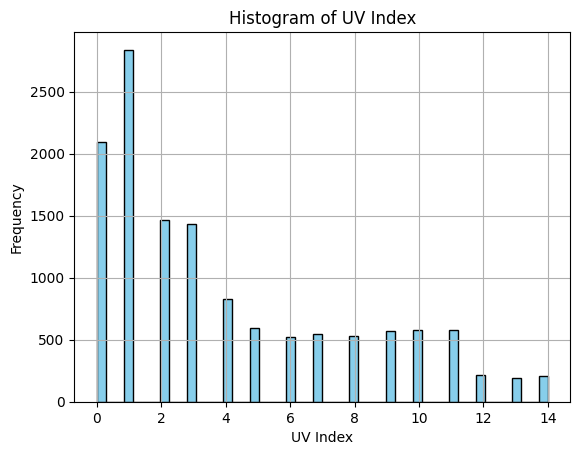

In [ ]:
dataset['UVIndex'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of UV Index')
plt.xlabel('UV Index')
plt.ylabel('Frequency')
plt.show() #Şekil 21

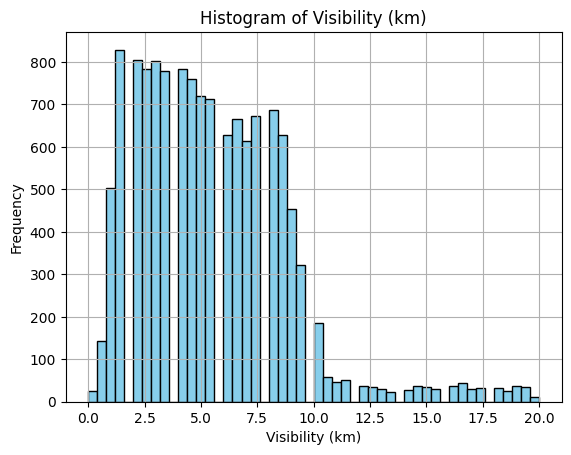

In [ ]:
dataset['VisibilityKilometer'].hist(bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Visibility (km)')
plt.xlabel('Visibility (km)')
plt.ylabel('Frequency')
plt.show() #Şekil 22

TARGET FEATURE

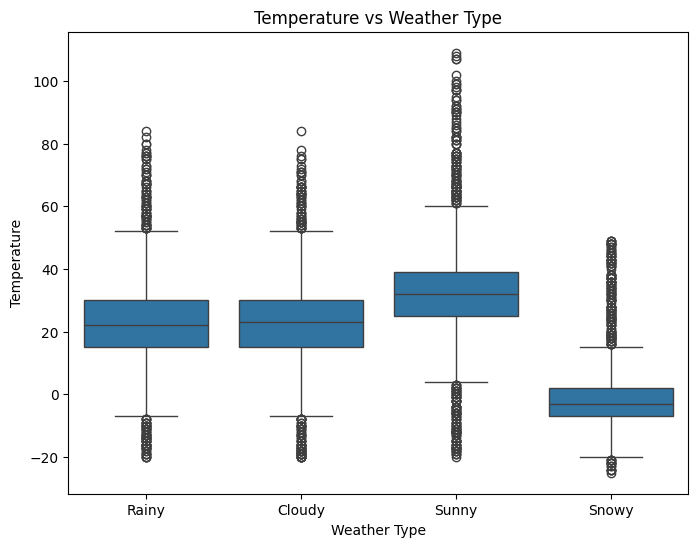

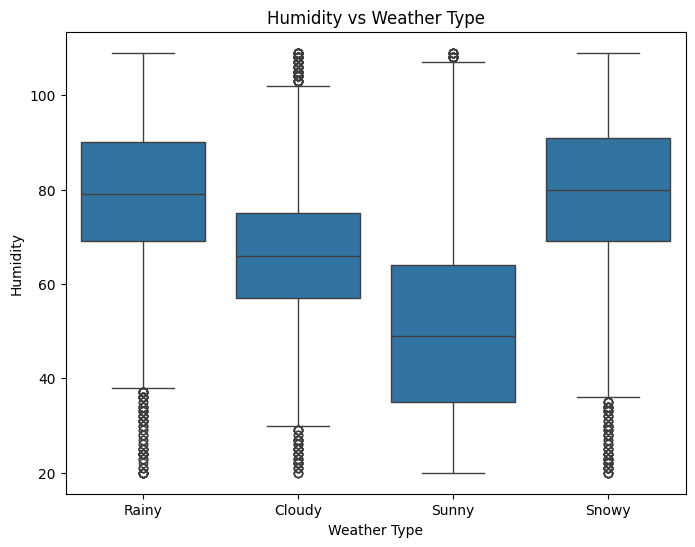

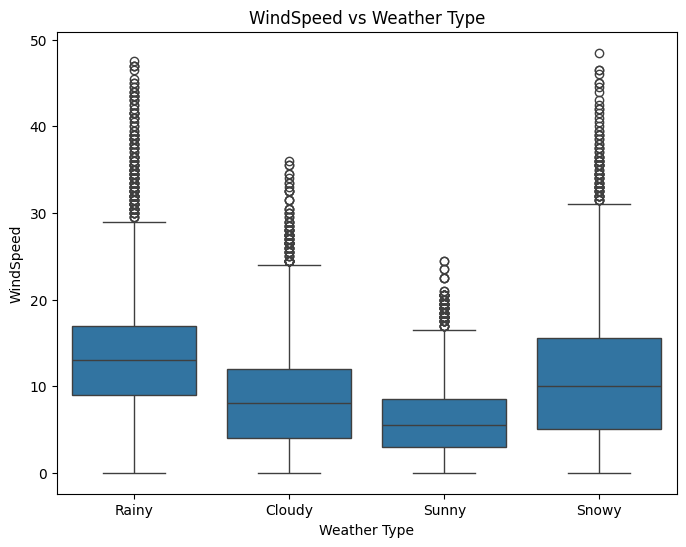

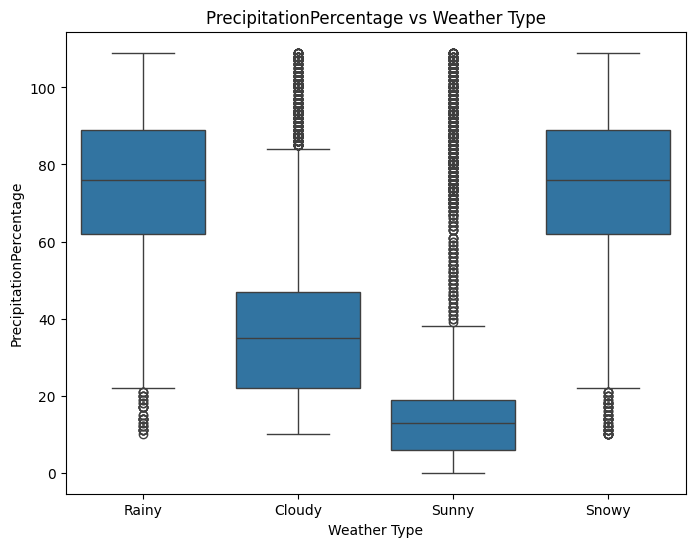

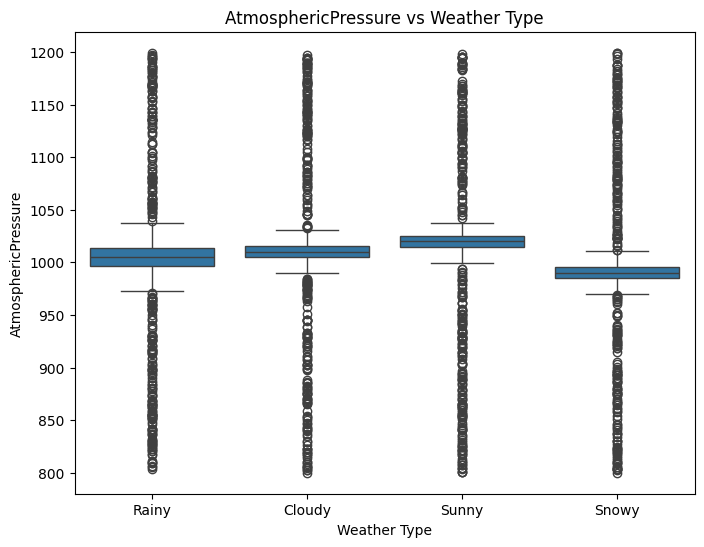

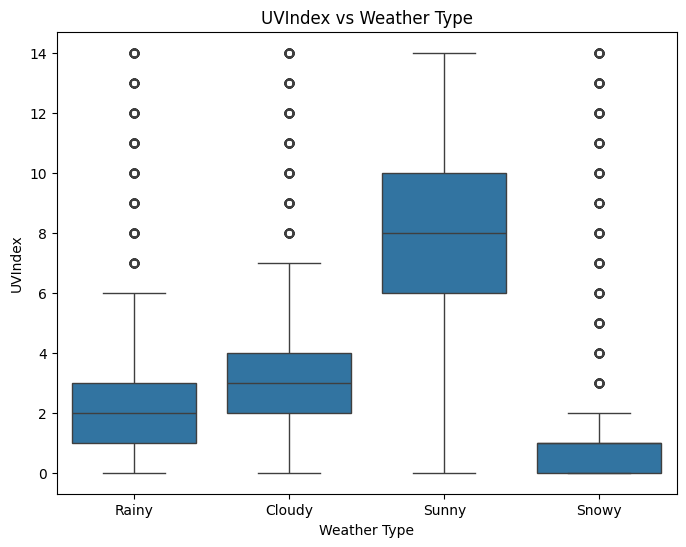

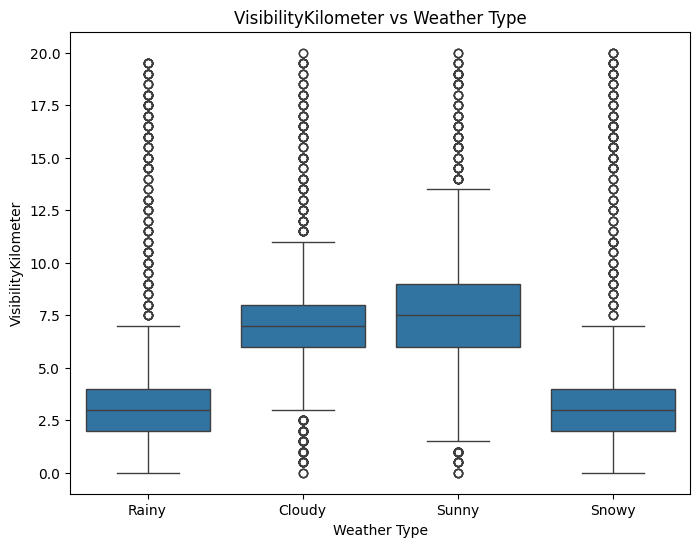

In [ ]:
numerical_features = ['Temperature', 'Humidity', 'WindSpeed', 'PrecipitationPercentage',
                      'AtmosphericPressure', 'UVIndex', 'VisibilityKilometer']

for feature in numerical_features:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='WeatherType', y=feature, data=dataset)
    plt.title(f'{feature} vs Weather Type')
    plt.xlabel('Weather Type')
    plt.ylabel(feature)
    plt.show()


Crosstab for CloudCover:
 WeatherType    Cloudy  Rainy  Snowy  Sunny
CloudCover                                
clear               0      0      0   2139
cloudy             92    105    107    107
overcast         1305   2193   2489    103
partly cloudy    1903   1002    704    951


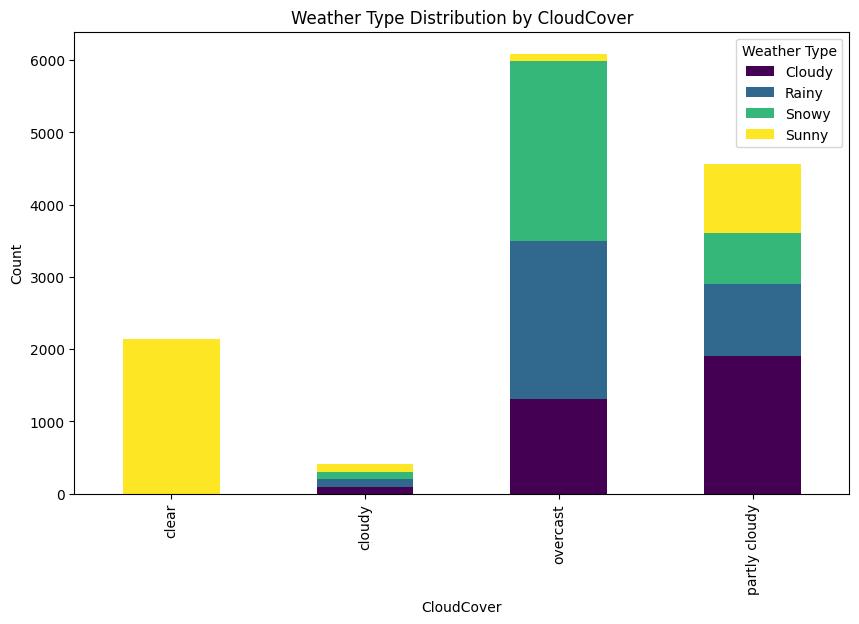


Crosstab for Season:
 WeatherType  Cloudy  Rainy  Snowy  Sunny
Season                                  
Autumn          806    796     69    829
Spring          850    831     80    837
Summer          766    820     65    841
Winter          878    853   3086    793


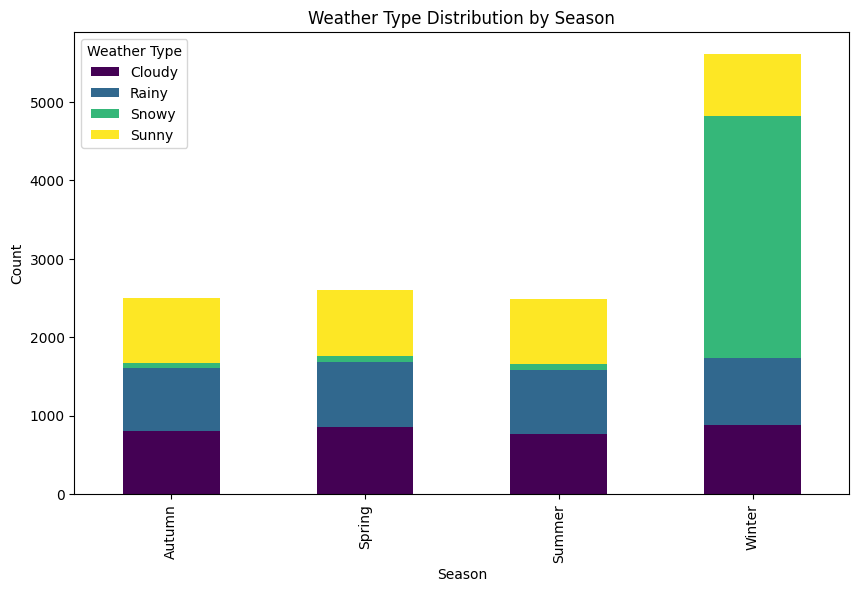


Crosstab for Location:
 WeatherType  Cloudy  Rainy  Snowy  Sunny
Location                                
coastal        1106   1216    120   1129
inland         1107   1069   1575   1065
mountain       1087   1015   1605   1106


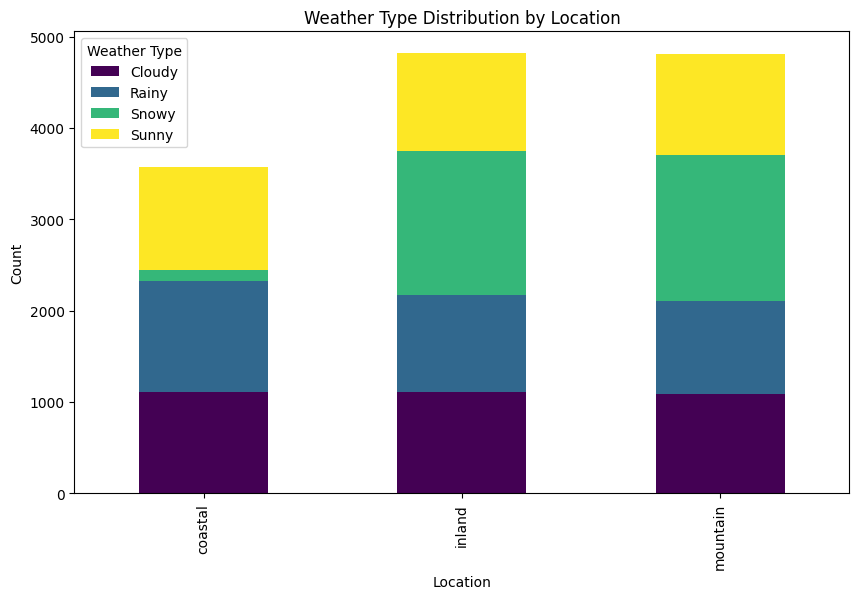

In [ ]:
categorical_features = ['CloudCover', 'Season', 'Location']

for feature in categorical_features:
    crosstab = pd.crosstab(dataset[feature], dataset['WeatherType'])
    print(f'\nCrosstab for {feature}:\n', crosstab)

    crosstab.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
    plt.title(f'Weather Type Distribution by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend(title='Weather Type')
    plt.show()

In [ ]:
from scipy.stats import pointbiserialr
#Change Weather Type to numeric format (e.g. "Rainy": 0, "Sunny": 1, etc.)
dataset['Weather Type Numeric'] = dataset['WeatherType'].astype('category').cat.codes
for feature in numerical_features:
    correlation, p_value = pointbiserialr(dataset['Weather Type Numeric'], dataset[feature])
    print(f'Correlation between Weather Type and {feature}: {correlation}')

Correlation between Weather Type and Temperature: 0.02892291837645104
Correlation between Weather Type and Humidity: -0.2505583529335717
Correlation between Weather Type and WindSpeed: -0.16648500230166374
Correlation between Weather Type and PrecipitationPercentage: -0.16157785512121742
Correlation between Weather Type and AtmosphericPressure: 0.030679302958603827
Correlation between Weather Type and UVIndex: 0.34580401961199553
Correlation between Weather Type and VisibilityKilometer: 0.04744762604389936


OTHER FEATURES

In [ ]:
import seaborn as sns

In [ ]:
correlation_matrix = dataset[numerical_features].corr() # Calculating correlation matrix

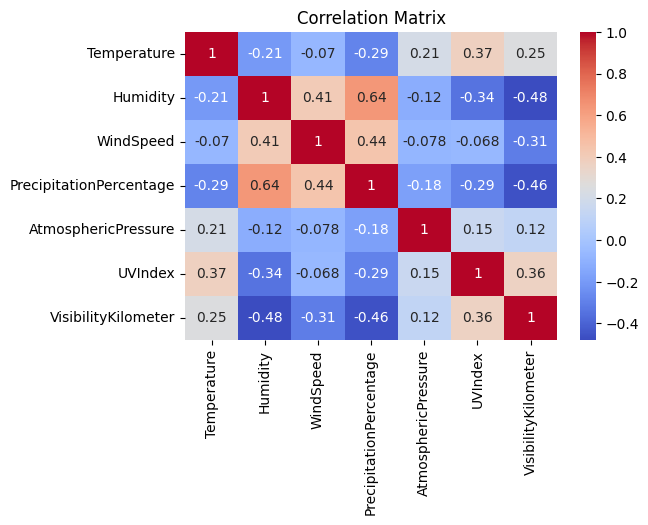

In [ ]:
#Visualizing with heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

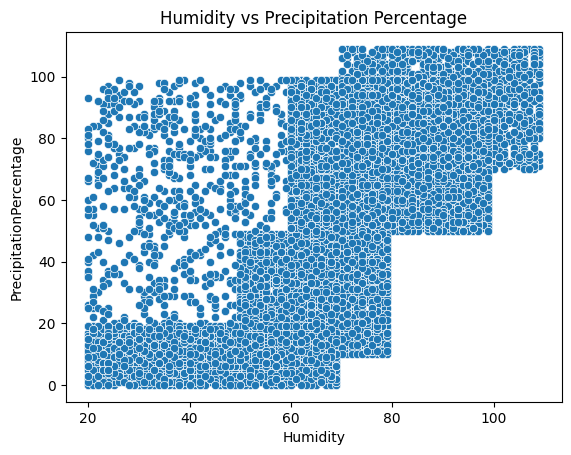

In [ ]:
#Look at the unlinear relationship between Humidity vs Precipitation Percentage
sns.scatterplot(x='Humidity', y='PrecipitationPercentage', data=dataset)
plt.title('Humidity vs Precipitation Percentage')
plt.show()

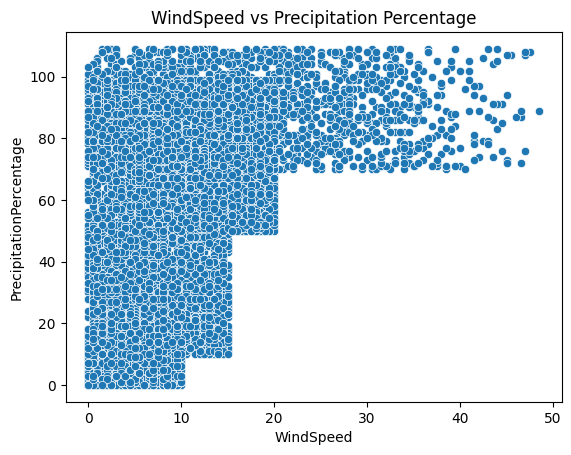

In [ ]:
#Look at the unlinear relationship between WindSpeed vs Precipitation Percentage
sns.scatterplot(x='WindSpeed', y='PrecipitationPercentage', data=dataset)
plt.title('WindSpeed vs Precipitation Percentage')
plt.show()

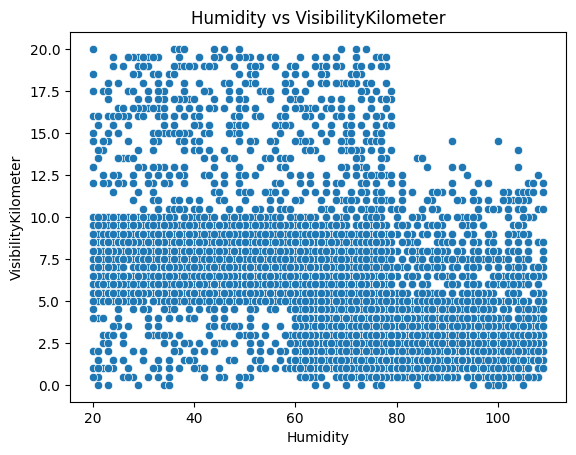

In [ ]:
#Look at the unlinear relationship between Humidity vs VisibilityKilometer
sns.scatterplot(x='Humidity', y='VisibilityKilometer', data=dataset)
plt.title('Humidity vs VisibilityKilometer')
plt.show()

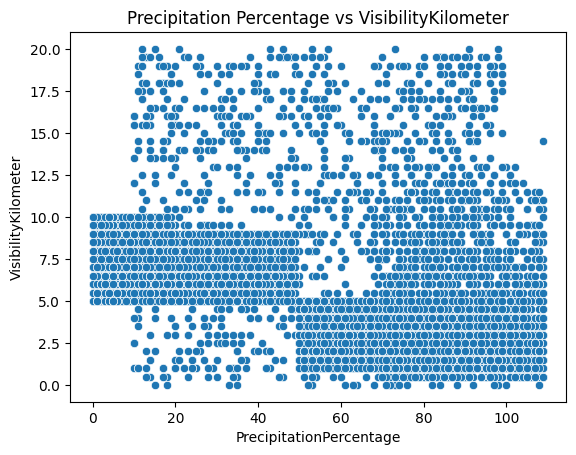

In [ ]:
#Look at the unlinear relationship between Precipitation Percentage vs VisibilityKilometer
sns.scatterplot(x='PrecipitationPercentage', y='VisibilityKilometer', data=dataset)
plt.title('Precipitation Percentage vs VisibilityKilometer')
plt.show()

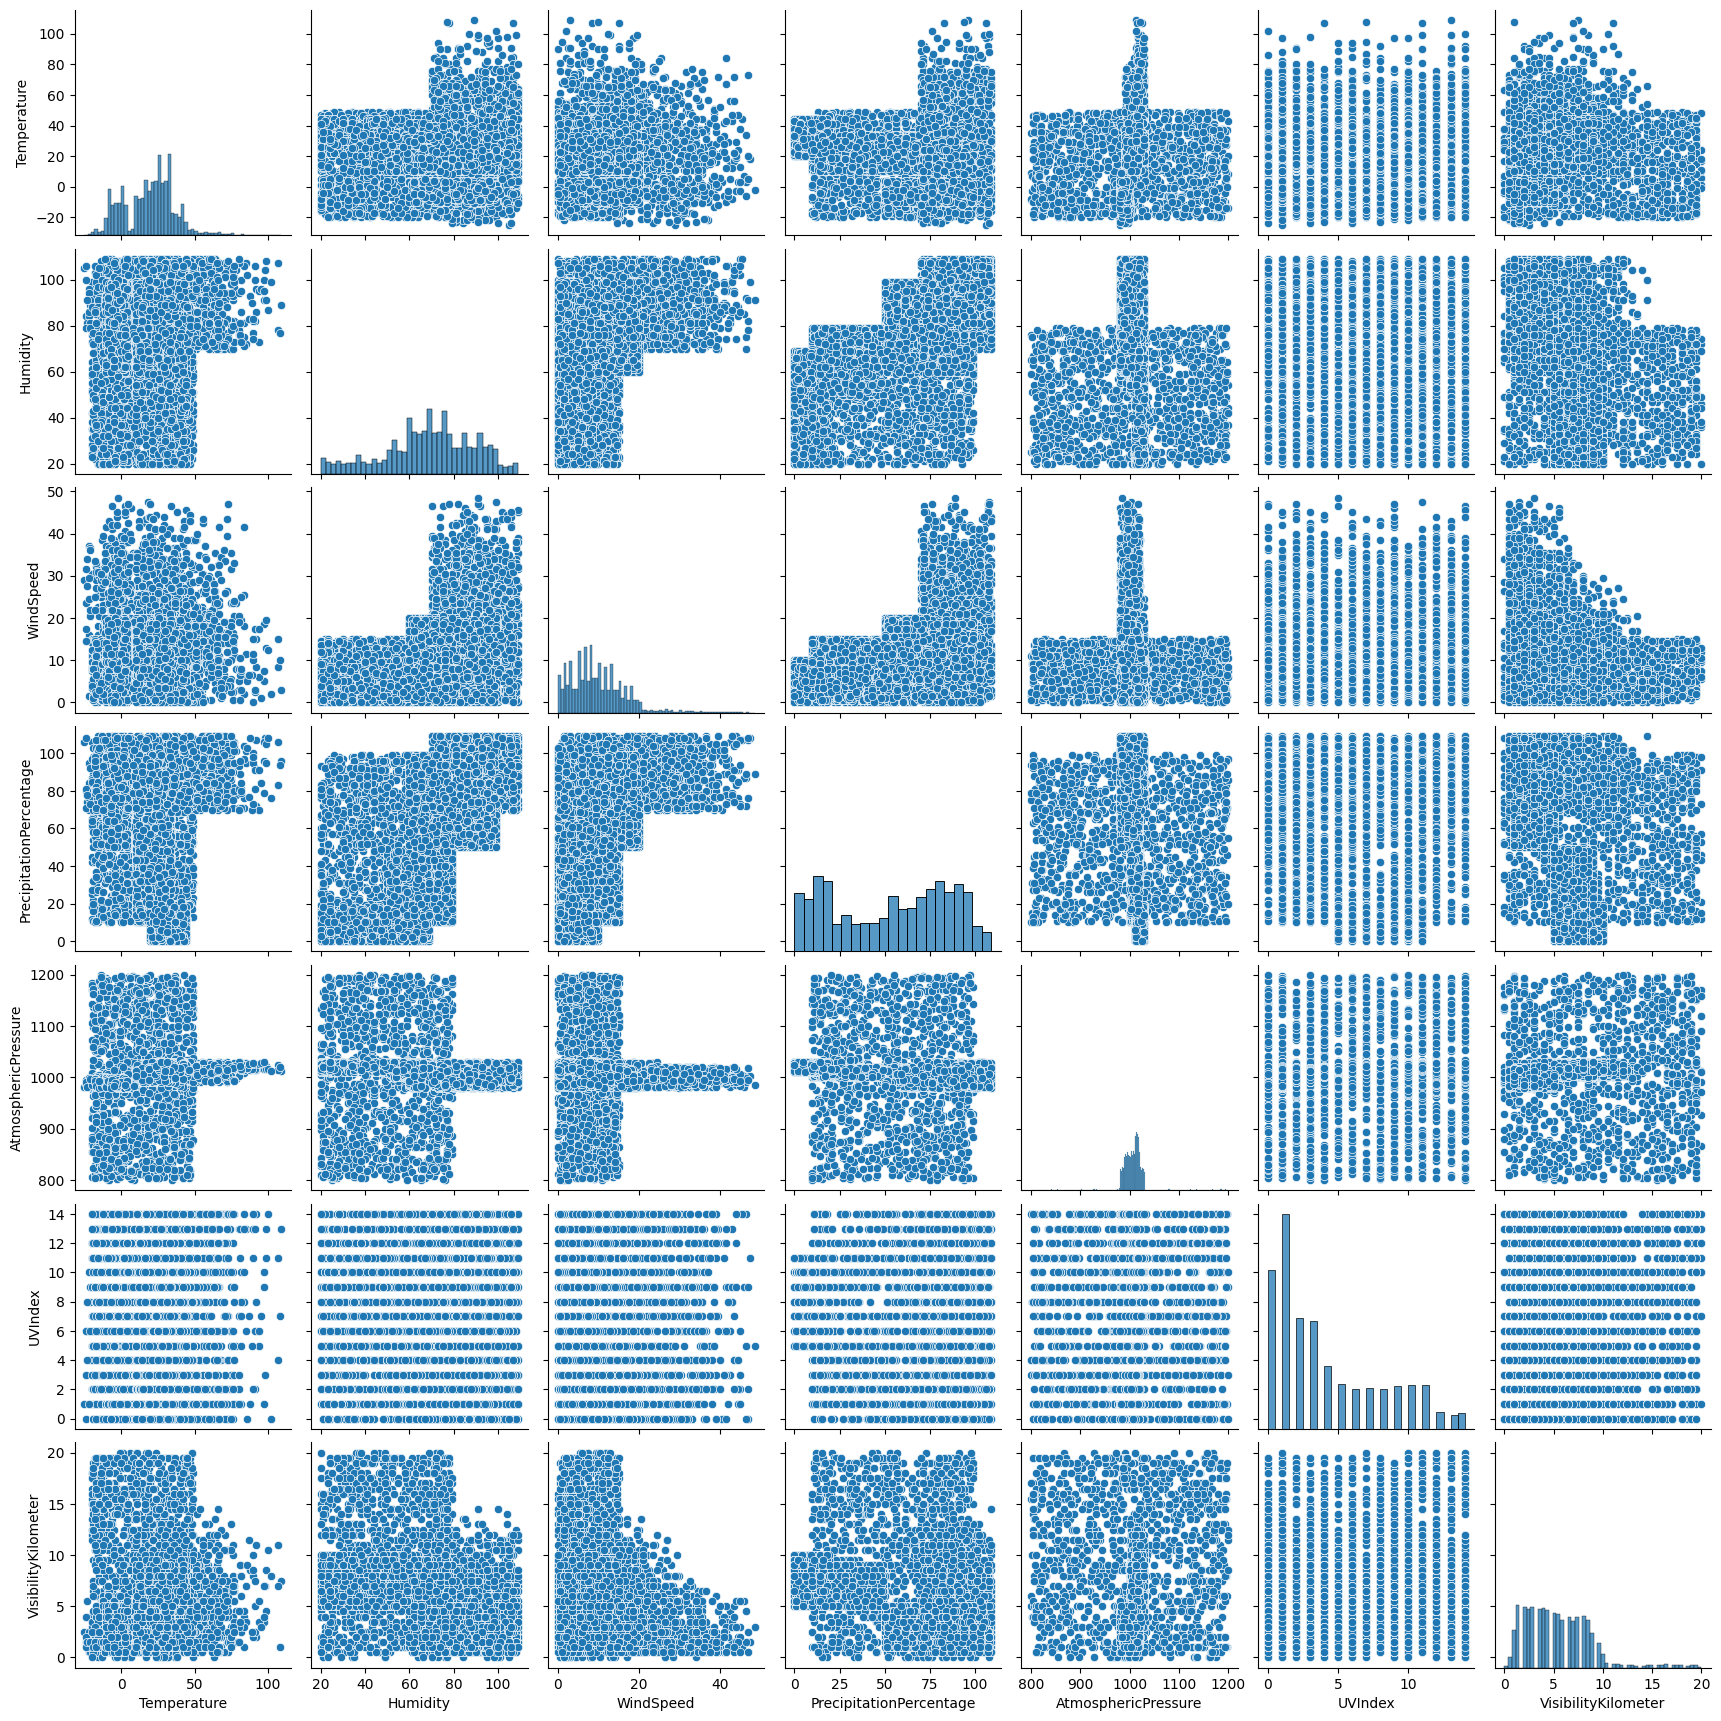

In [ ]:
#Relationships between all numeric columns
sns.pairplot(dataset[numerical_features])
plt.show()

OUTLIER DETECTION AND HANDLING

In [ ]:
#The function that removes outliers from the specified column in the DataFrame by replacing them with the column's median value.
def replace_outliers_with_median(dataset, column_name, lower_limit, upper_limit):

    #Removes outliers from the specified column in the DataFrame by replacing them with the column's median value.

    # Replace outliers with the median value of the column
    median_value = dataset[column_name].median() #Getting median value of the column

    dataset[column_name] = np.where(dataset[column_name] > upper_limit, median_value, dataset[column_name])
    dataset[column_name] = np.where(dataset[column_name] < lower_limit, median_value, dataset[column_name])


Outlier Detection of Temperature Attribute

In [ ]:
tempQ1=dataset.Temperature.quantile(0.25) #initializing the q1 of temperature
tempQ3=dataset.Temperature.quantile(0.75) #initializing the q3 of temperature
tempQ1,tempQ3

(4.0, 31.0)

In [ ]:
tempIQR=tempQ3-tempQ1   #calculating the IQR
tempIQR

27.0

In [ ]:
lowerLimitTemp=tempQ1-1.5*tempIQR  #calculating lower limit
upperLimitTemp=tempQ3+1.5*tempIQR  #calculating upper limit
lowerLimitTemp,upperLimitTemp

(-36.5, 71.5)

<Axes: ylabel='Temperature'>

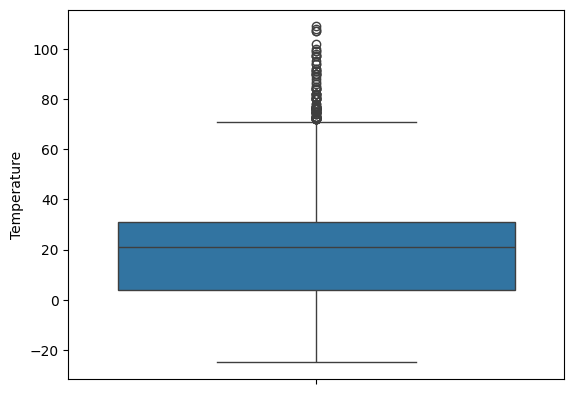

In [ ]:
sns.boxplot(dataset['Temperature'])  #To see the boxplot of IQR

In [ ]:
dataset[(dataset.Temperature<lowerLimitTemp) | (dataset.Temperature>upperLimitTemp)] #see the outliers

,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location,WeatherType,Weather Type Numeric
210,78.0,81,8.0,78.0,overcast,1010.19,1,Autumn,4.5,inland,Cloudy,0
228,73.0,82,47.0,107.0,overcast,1002.73,0,Winter,0.5,mountain,Rainy,1
535,80.0,76,3.0,93.0,clear,1014.26,13,Winter,3.0,inland,Sunny,3
709,74.0,101,18.0,76.0,partly cloudy,1010.82,6,Spring,4.0,coastal,Sunny,3
730,76.0,91,13.5,82.0,partly cloudy,1015.18,1,Autumn,7.0,inland,Cloudy,0
...,...,...,...,...,...,...,...,...,...,...,...,...
12752,90.0,83,15.0,98.0,clear,1028.13,2,Summer,10.0,inland,Sunny,3
12814,72.0,88,12.0,83.0,clear,1015.17,13,Winter,5.5,coastal,Sunny,3
12878,95.0,96,1.0,84.0,partly cloudy,1027.98,7,Spring,3.0,mountain,Sunny,3
13065,97.0,95,7.5,79.0,clear,1029.30,9,Winter,4.0,mountain,Sunny,3


<Axes: ylabel='Temperature'>

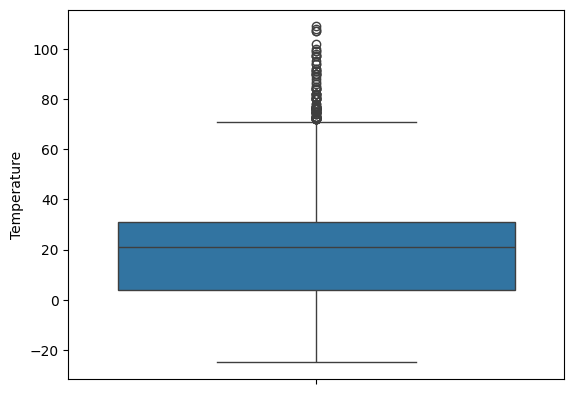

In [ ]:
sns.boxplot(dataset['Temperature'])  #To see the boxplot of IQR after the imputation

Outlier Detection of Wind Speed Attribute

In [ ]:
windQ1=dataset.WindSpeed.quantile(0.25) #initializing the q1 of WindSpeed
windQ3=dataset.WindSpeed.quantile(0.75) #initializing the q3 of WindSpeed
windQ1,windQ3

(5.0, 13.5)

In [ ]:
windIQR=windQ3-windQ1   #calculating the IQR
windIQR

8.5

In [ ]:
lowerLimitWind=windQ1-1.5*windIQR  #calculating lower limit
upperLimitWind=windQ3+1.5*windIQR  #calculating upper limit
lowerLimitWind,upperLimitWind

(-7.75, 26.25)

<Axes: ylabel='WindSpeed'>

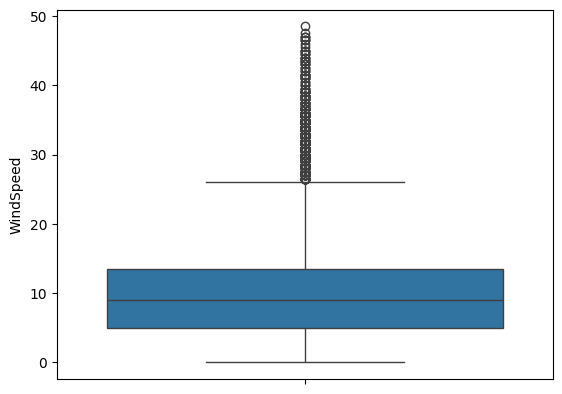

In [ ]:
sns.boxplot(dataset['WindSpeed'])  #To see the boxplot of IQR


In [ ]:
dataset[(dataset.WindSpeed<lowerLimitWind) | (dataset.WindSpeed>upperLimitWind)] #see the outliers

,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location,WeatherType,Weather Type Numeric
63,3.0,75,46.5,87.0,overcast,996.85,5,Winter,4.5,inland,Snowy,2
90,15.0,81,28.5,71.0,partly cloudy,1008.00,4,Winter,6.0,inland,Cloudy,0
123,-3.0,92,28.0,99.0,partly cloudy,987.70,1,Winter,4.5,mountain,Snowy,2
208,34.0,99,34.0,74.0,partly cloudy,1016.03,9,Autumn,1.0,inland,Rainy,1
228,73.0,82,47.0,107.0,overcast,1002.73,0,Winter,0.5,mountain,Rainy,1
...,...,...,...,...,...,...,...,...,...,...,...,...
12999,-2.0,90,28.5,84.0,overcast,992.14,14,Winter,4.5,mountain,Snowy,2
13066,5.0,102,31.0,108.0,partly cloudy,1005.89,10,Summer,2.0,inland,Rainy,1
13113,42.0,106,32.5,103.0,partly cloudy,996.45,14,Spring,1.0,mountain,Rainy,1
13115,40.0,75,26.5,78.0,partly cloudy,1011.36,0,Spring,4.5,mountain,Cloudy,0


<Axes: ylabel='WindSpeed'>

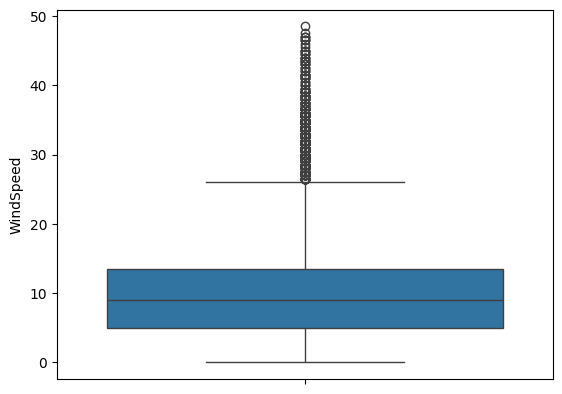

In [ ]:
sns.boxplot(dataset['WindSpeed'])  #To see the boxplot of IQR after the imputation

Outlier Detection of Precipitation Attribute




In [ ]:
precQ1=dataset.PrecipitationPercentage.quantile(0.25) #initializing the q1 of Precipitation
precQ3=dataset.PrecipitationPercentage.quantile(0.75) #initializing the q3 of Precipitation
precQ1,precQ3

(19.0, 82.0)

In [ ]:
precIQR=precQ3-precQ1   #calculating the IQR
precIQR

63.0

In [ ]:
lowerLimitPrec=precQ1-1.5*precIQR  #calculating lower limit
upperLimitPrec=precQ3+1.5*precIQR  #calculating upper limit
lowerLimitPrec,upperLimitPrec

(-75.5, 176.5)

In [ ]:
dataset[(dataset.PrecipitationPercentage<lowerLimitPrec) | (dataset.PrecipitationPercentage>upperLimitPrec)] #see the outliers


,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location,WeatherType,Weather Type Numeric


*there is no outlier in the precipitation*

Outlier Detection of Atmospheric Pressure Attribute

In [ ]:
atmQ1=dataset.AtmosphericPressure.quantile(0.25) #initializing the q1 of Atmospheric Pressure
atmQ3=dataset.AtmosphericPressure.quantile(0.75) #initializing the q3 of Atmospheric Pressure
atmQ1,atmQ3

(994.8, 1016.7725)

In [ ]:
atmIQR=atmQ3-atmQ1   #calculating the IQR
atmIQR

21.972500000000082

In [ ]:
lowerLimitAtm=atmQ1-1.5*atmIQR  #calculating lower limit
upperLimitAtm=atmQ3+1.5*atmIQR  #calculating upper limit
lowerLimitAtm,upperLimitAtm

(961.8412499999998, 1049.7312500000003)

<Axes: ylabel='AtmosphericPressure'>

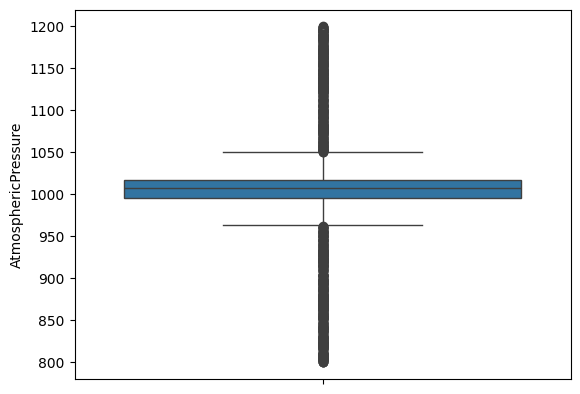

In [ ]:
sns.boxplot(dataset['AtmosphericPressure'])  #To see the boxplot of IQR

In [ ]:
dataset[(dataset.AtmosphericPressure<lowerLimitAtm) | (dataset.AtmosphericPressure>upperLimitAtm)] #see the outliers


,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location,WeatherType,Weather Type Numeric
10,35.0,45,6.0,86.0,partly cloudy,879.88,2,Spring,1.0,mountain,Cloudy,0
38,-9.0,49,1.5,58.0,partly cloudy,1132.20,8,Spring,16.5,mountain,Snowy,2
58,31.0,70,0.5,69.0,overcast,1074.07,3,Spring,12.5,inland,Sunny,3
72,11.0,52,6.0,97.0,overcast,1063.39,7,Summer,12.5,inland,Snowy,2
85,32.0,35,2.5,63.0,partly cloudy,1160.48,2,Winter,0.0,coastal,Sunny,3
...,...,...,...,...,...,...,...,...,...,...,...,...
13167,33.0,73,5.0,31.0,partly cloudy,840.06,9,Spring,10.5,coastal,Cloudy,0
13168,44.0,45,7.0,28.0,partly cloudy,894.65,5,Spring,11.5,inland,Sunny,3
13178,0.0,50,11.5,82.0,cloudy,822.40,8,Spring,15.5,coastal,Cloudy,0
13184,3.0,62,7.5,14.0,overcast,1128.35,3,Summer,7.5,mountain,Rainy,1


<Axes: ylabel='AtmosphericPressure'>

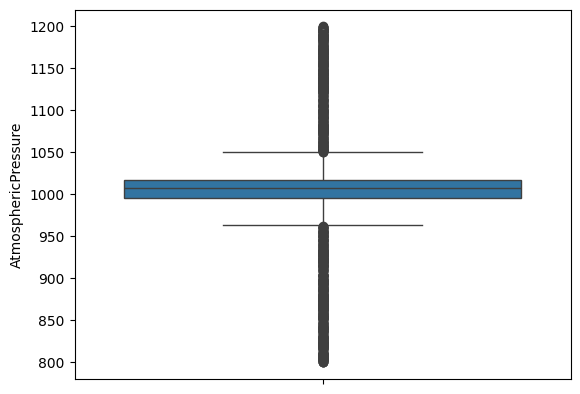

In [ ]:
sns.boxplot(dataset['AtmosphericPressure'])  #To see the boxplot of IQR after the imputation

Outlier Detection of Visibility Attribute

In [ ]:
visQ1=dataset.VisibilityKilometer.quantile(0.25) #initializing the q1 of VisibilityKilometer
visQ3=dataset.VisibilityKilometer.quantile(0.75) #initializing the q3 of VisibilityKilometer
visQ1,visQ3

(3.0, 7.5)

In [ ]:
visIQR=visQ3-visQ1   #calculating the IQR
visIQR

4.5

In [ ]:
lowerLimitVis=visQ1-1.5*visIQR  #calculating lower limit
upperLimitVis=visQ3+1.5*visIQR  #calculating upper limit
lowerLimitVis,upperLimitVis

(-3.75, 14.25)

<Axes: ylabel='VisibilityKilometer'>

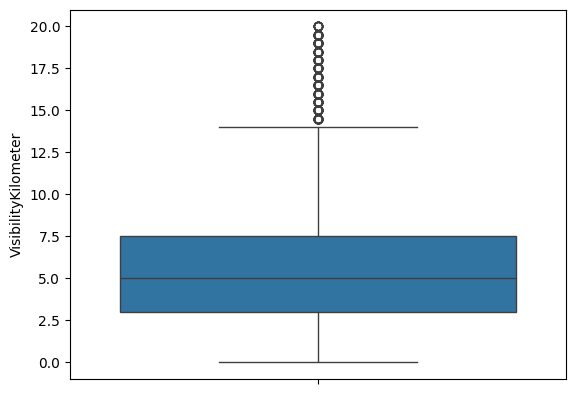

In [ ]:
sns.boxplot(dataset['VisibilityKilometer'])  #To see the boxplot of IQR

In [ ]:
dataset[(dataset.VisibilityKilometer<lowerLimitVis) | (dataset.VisibilityKilometer>upperLimitVis)] #see the outliers


,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location,WeatherType,Weather Type Numeric
38,-9.0,49,1.5,58.0,partly cloudy,1132.20,8,Spring,16.5,mountain,Snowy,2
113,18.0,60,12.5,42.0,overcast,822.66,2,Summer,17.5,mountain,Rainy,1
134,29.0,77,0.5,91.0,cloudy,934.49,14,Autumn,17.0,inland,Sunny,3
300,48.0,79,12.0,88.0,partly cloudy,1140.24,4,Autumn,17.0,mountain,Snowy,2
359,5.0,36,14.5,68.0,cloudy,1195.34,1,Autumn,16.0,inland,Rainy,1
...,...,...,...,...,...,...,...,...,...,...,...,...
13018,-9.0,32,5.0,21.0,partly cloudy,966.64,11,Spring,16.5,coastal,Snowy,2
13025,66.0,100,7.0,109.0,clear,1018.30,12,Autumn,14.5,mountain,Sunny,3
13083,16.0,71,3.0,43.0,overcast,920.13,10,Summer,15.0,inland,Cloudy,0
13163,5.0,67,9.5,71.0,partly cloudy,1122.86,4,Spring,15.0,mountain,Cloudy,0


<Axes: ylabel='VisibilityKilometer'>

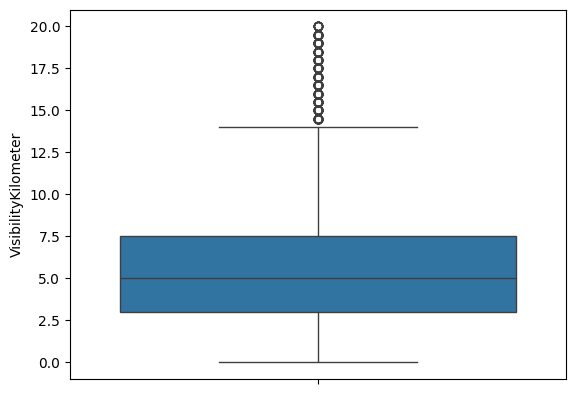

In [ ]:
sns.boxplot(dataset['VisibilityKilometer'])  #To see the boxplot of IQR after the imputation

SPLITTING DATASET INTO DEPENDENT AND INDEPENDENT VARIABLES

In [ ]:
X=dataset.iloc[: , :-2]  #Extracting all rows and columns from the dataset except the last column
y=dataset.iloc[: , -1]  #Extracting the all rows and just last column

In [ ]:
# To see all the columns
pd.set_option('display.max_columns', None)  # Remove the column view orders
pd.set_option('display.width', 1000)

In [ ]:
print(X)  # Dataframe of independent features

       Temperature  Humidity  WindSpeed  PrecipitationPercentage     CloudCover  AtmosphericPressure  UVIndex  Season  VisibilityKilometer  Location
0             14.0        73        9.5                     82.0  partly cloudy              1010.82        2  Winter                  3.5    inland
1             39.0        96        8.5                     71.0  partly cloudy              1011.43        7  Spring                 10.0    inland
2             30.0        64        7.0                     16.0          clear              1018.72        5  Spring                  5.5  mountain
3             38.0        83        1.5                     82.0          clear              1026.25        7  Spring                  1.0   coastal
4             27.0        74       17.0                     66.0       overcast               990.67        1  Winter                  2.5  mountain
...            ...       ...        ...                      ...            ...                  ...      

In [ ]:
print(y)  # Dependent variable vector

0        1
1        0
2        3
3        3
4        1
        ..
13195    1
13196    2
13197    0
13198    2
13199    1
Name: Weather Type Numeric, Length: 13200, dtype: int8


**REPLACE OUTLIER VALUES WITH MEDIAN**

In [ ]:
replace_outliers_with_median(dataset,"WindSpeed",lowerLimitWind,upperLimitWind)  #Replace the outliers with median values
replace_outliers_with_median(dataset,"AtmosphericPressure",lowerLimitAtm,upperLimitAtm)  #Replace the outliers with median values
replace_outliers_with_median(dataset,"VisibilityKilometer",lowerLimitVis,upperLimitVis)  #Replace the outliers with median values
replace_outliers_with_median(dataset,"Temperature",lowerLimitTemp,upperLimitTemp)  #Replace the outliers with median values

ENCODING CATEGORICAL DATA

Encoding Cloud Cover With Ordinal Encoding


In [ ]:
X['CloudCover'].unique()  # Getting the unique values of 'cloud cover' column


array(['partly cloudy', 'clear', 'overcast', 'cloudy'], dtype=object)

In [ ]:
ranking=['clear','partly cloudy', 'cloudy' ,'overcast']  # Ordering the values according to cloud rate (For ordinal encoding)

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
enc= OrdinalEncoder(categories=[ranking])  # Indicating ranking of the cloud cover

In [ ]:
enc.fit_transform(X[['CloudCover']]) # Transforming to numeric values (Input is a dataframe )


array([[1.],
       [1.],
       [0.],
       ...,
       [3.],
       [3.],
       [3.]])

In [ ]:
X['CloudCover']=enc.fit_transform(X[['CloudCover']]) # Changing the 'Cloud Cover' column with the numeric values

In [ ]:
X.head()

,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location
0,14.0,73,9.5,82.0,1.0,1010.82,2,Winter,3.5,inland
1,39.0,96,8.5,71.0,1.0,1011.43,7,Spring,10.0,inland
2,30.0,64,7.0,16.0,0.0,1018.72,5,Spring,5.5,mountain
3,38.0,83,1.5,82.0,0.0,1026.25,7,Spring,1.0,coastal
4,27.0,74,17.0,66.0,3.0,990.67,1,Winter,2.5,mountain


Encoding Season With Ordinal Encoding


In [ ]:
X['Season'].unique()

array(['Winter', 'Spring', 'Summer', 'Autumn'], dtype=object)

In [ ]:
seasons=['Spring','Summer','Autumn','Winter' ] #Ordering the seasons

In [ ]:
enc=OrdinalEncoder(categories=[seasons]) # Indicating the order of the seasons

In [ ]:
enc.fit_transform(X[['Season']]) # Transforming to numeric values

array([[3.],
       [0.],
       [0.],
       ...,
       [2.],
       [3.],
       [2.]])

In [ ]:
X['Season']= enc.fit_transform(X[['Season']]) # Changing the 'Season' column with the numeric values


In [ ]:
X.head()

,Temperature,Humidity,WindSpeed,PrecipitationPercentage,CloudCover,AtmosphericPressure,UVIndex,Season,VisibilityKilometer,Location
0,14.0,73,9.5,82.0,1.0,1010.82,2,3.0,3.5,inland
1,39.0,96,8.5,71.0,1.0,1011.43,7,0.0,10.0,inland
2,30.0,64,7.0,16.0,0.0,1018.72,5,0.0,5.5,mountain
3,38.0,83,1.5,82.0,0.0,1026.25,7,0.0,1.0,coastal
4,27.0,74,17.0,66.0,3.0,990.67,1,3.0,2.5,mountain


Encoding Location With One Hot Encoding

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder   #importing the necessary libraries

In [ ]:
column_index = X.columns.get_loc('Location')  # Getting the index of location column
print(column_index)

9


In [ ]:
ct=ColumnTransformer([('encoder',OneHotEncoder(),[column_index])], remainder="passthrough") #passthrough means dont drop the rest of the columns (default drop)

In [ ]:
X_transformed=ct.fit_transform(X) # Transforming to numeric values

In [ ]:
feature_names = ct.get_feature_names_out() #Getting the new column names after the transformation
X = pd.DataFrame(X_transformed, columns=feature_names) #Converting back to dataframe (x_transformed is numpy array)

In [ ]:
print(X.head())

   encoder__Location_coastal  encoder__Location_inland  encoder__Location_mountain  remainder__Temperature  remainder__Humidity  remainder__WindSpeed  remainder__PrecipitationPercentage  remainder__CloudCover  remainder__AtmosphericPressure  remainder__UVIndex  remainder__Season  remainder__VisibilityKilometer
0                        0.0                       1.0                         0.0                    14.0                 73.0                   9.5                                82.0                    1.0                         1010.82                 2.0                3.0                             3.5
1                        0.0                       1.0                         0.0                    39.0                 96.0                   8.5                                71.0                    1.0                         1011.43                 7.0                0.0                            10.0
2                        0.0                       0.0          

Encoding Weather Type with Label Encoding




In [ ]:
from sklearn.preprocessing import LabelEncoder #importing the library

In [ ]:
le=LabelEncoder() #initializing label encoder

In [ ]:
y=le.fit_transform(y) #applying encoding to y

In [ ]:
print(y)

[1 0 3 ... 0 2 1]


SPLITTING DATA INTO TRAIN AND TEST SET

In [ ]:
from sklearn.model_selection import train_test_split # importing the library

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=1) #splitting the X and y into the test and train sets

In [ ]:
print(x_train)



       encoder__Location_coastal  encoder__Location_inland  encoder__Location_mountain  remainder__Temperature  remainder__Humidity  remainder__WindSpeed  remainder__PrecipitationPercentage  remainder__CloudCover  remainder__AtmosphericPressure  remainder__UVIndex  remainder__Season  remainder__VisibilityKilometer
3406                         0.0                       1.0                         0.0                    25.0                 63.0                   4.0                                 0.0                    0.0                         1022.50                 6.0                0.0                             9.5
5748                         1.0                       0.0                         0.0                    11.0                 55.0                   6.0                                48.0                    1.0                         1013.87                 1.0                1.0                             6.0
3755                         0.0                    

In [ ]:
print(x_test)


       encoder__Location_coastal  encoder__Location_inland  encoder__Location_mountain  remainder__Temperature  remainder__Humidity  remainder__WindSpeed  remainder__PrecipitationPercentage  remainder__CloudCover  remainder__AtmosphericPressure  remainder__UVIndex  remainder__Season  remainder__VisibilityKilometer
8308                         1.0                       0.0                         0.0                    10.0                 60.0                   9.0                                78.0                    3.0                         1011.26                 1.0                3.0                             3.5
5721                         1.0                       0.0                         0.0                    32.0                 84.0                  15.0                                84.0                    3.0                          996.73                 3.0                0.0                             1.0
10917                        0.0                    

In [ ]:
print(y_train)


[3 0 1 ... 3 3 0]


In [ ]:
print(y_test)

[1 1 2 ... 0 2 3]


FEATURE SCALING (STANDARDIZATION)

In [ ]:
from sklearn.preprocessing import StandardScaler #importing the library

In [ ]:
scaler=StandardScaler() #creating scaler instance for StandardScaler

In [ ]:
numerical_columns = ['remainder__Temperature', 'remainder__Humidity', 'remainder__WindSpeed', 'remainder__PrecipitationPercentage', 'remainder__AtmosphericPressure','remainder__UVIndex', 'remainder__VisibilityKilometer']
#indicating the numeric columns

In [ ]:
x_train[numerical_columns] = scaler.fit_transform(x_train[numerical_columns]) #apply standardization to the x_train
x_test[numerical_columns] = scaler.fit_transform(x_test[numerical_columns])   #apply standardization to the x_test
print("Standartlaştırılmış Eğitim Seti:\n", x_train[numerical_columns].head())
print("Standartlaştırılmış Test Seti:\n", x_test[numerical_columns].head())


Standartlaştırılmış Eğitim Seti:
        remainder__Temperature  remainder__Humidity  remainder__WindSpeed  remainder__PrecipitationPercentage  remainder__AtmosphericPressure  remainder__UVIndex  remainder__VisibilityKilometer
3406                 0.335275            -0.279438             -0.842517                           -1.676404                        0.453749            0.513539                        1.197002
5748                -0.473897            -0.675550             -0.552128                           -0.170672                        0.219467           -0.783806                        0.158164
3755                 0.566467             1.106951             -0.406933                            0.299869                        0.383980           -0.524337                       -0.732268
10930                0.624265             1.305006             -0.624725                            0.393978                        0.060927           -0.524337                       -1.177485
6

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (13200, 12)
y shape: (13200,)


IMPLEMENTING MODELS

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier   #importing the library for decision tree

Finding the Best Parameters with Grid Search

In [ ]:
from sklearn.model_selection import GridSearchCV

# Parameters
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

# GridSearch
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring="accuracy")
grid_search.fit(x_train, y_train)

# Print the best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

# Standard deviation for best parameters
best_index = grid_search.best_index_  # Best result index
std_dev = grid_search.cv_results_['std_test_score'][best_index]  # Standart sapma
print("Standard Deviation for Best Parameters:", std_dev)

In [ ]:
dtc=DecisionTreeClassifier(**best_params) #Model building

In [ ]:
dtc.fit(x_train,y_train)

DecisionTreeClassifier()

In [ ]:
y_pred_dtc=dtc.predict(x_test)  #Do the prediction

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
conf_matrix=confusion_matrix(y_test,y_pred_dtc)
print(conf_matrix)

[[749  45  21  27]
 [ 57 741  24  24]
 [ 15  23 768  14]
 [ 21  16  19 736]]


In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, cmap="YlGnBu", fmt="d")
plt.title("Confusion Matrix Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

In [ ]:
print(classification_report(y_test,y_pred_dtc))

              precision    recall  f1-score   support

           0       0.89      0.89      0.89       842
           1       0.90      0.88      0.89       846
           2       0.92      0.94      0.93       820
           3       0.92      0.93      0.92       792

    accuracy                           0.91      3300
   macro avg       0.91      0.91      0.91      3300
weighted avg       0.91      0.91      0.91      3300



In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy_score(y_test,y_pred_dtc)

0.9072727272727272

In [ ]:
dtc.feature_importances_   #to see the importances of features to the model

array([0.00229702, 0.00265452, 0.00185063, 0.28222403, 0.03130537,
       0.02637074, 0.08467873, 0.04324699, 0.03382506, 0.22742115,
       0.02723885, 0.23688689])

In [ ]:
features=pd.DataFrame(dtc.feature_importances_,x_train.columns)

In [ ]:
features.head(15)

,0
encoder__Location_coastal,0.002297
encoder__Location_inland,0.002655
encoder__Location_mountain,0.001851
remainder__Temperature,0.282224
remainder__Humidity,0.031305
remainder__WindSpeed,0.026371
remainder__PrecipitationPercentage,0.084679
remainder__CloudCover,0.043247
remainder__AtmosphericPressure,0.033825
remainder__UVIndex,0.227421


In [ ]:
# Feature İmportances to the model
feature_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": dtc.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feature_importance, palette="viridis")
plt.title("Feature Importance")
plt.xlabel("Importance Degree")
plt.ylabel("Feature")
plt.show()

In [ ]:
#Test set accuracy
best_model = grid_search.best_estimator_
test_accuracy = best_model.score(x_test, y_test)
print("Test Set Accuracy DT:", test_accuracy)

#Train set accuracy
train_accuracy = best_model.score(x_train, y_train)
print("Train Set Accuracy DT:", train_accuracy)

K Nearest Neighbors (KNN)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier  #import the knn library

Finding the Best Parameters with Grid Search

In [ ]:
# Parameters
param_grid = {
    "n_neighbors": [3, 5, 7, 9],       # Nighbour numbers
    "weights": ["uniform", "distance"], # Weighting type
    "metric": ["euclidean", "manhattan", "minkowski"]  # Distance
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,  # 5 cross val
    scoring="accuracy"  # Performance metric
)
grid_search.fit(x_train, y_train)

# Best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

# Calculate the standart dev for best parameters
best_index = grid_search.best_index_  # The index for best result
std_dev = grid_search.cv_results_['std_test_score'][best_index]  # standart dev
print("Standard Deviation for Best Parameters:", std_dev)


In [ ]:
# Change the parameter
best_params['n_neighbors'] = 7  # New nighbour value

In [ ]:
#knn=KNeighborsClassifier(**best_params)  Overfitting occured
knn=KNeighborsClassifier(n_neighbors=8)

In [ ]:
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=8)

In [ ]:
y_pred_knn=knn.predict(x_test) #Prediction

In [ ]:
print(y_pred_knn)

[1 1 2 ... 0 2 3]


In [ ]:
knn.score(x_test,y_test)  #How accurate it is

0.8975757575757576

In [ ]:
conf_matrix_knn=confusion_matrix(y_test,y_pred_knn)


In [ ]:
print(conf_matrix_knn)

[[739  64  18  21]
 [ 50 748  31  17]
 [ 21  20 763  16]
 [ 41  32   7 712]]


In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_knn, annot=True, cmap="YlGnBu", fmt="d")
plt.title("Confusion Matrix KNN")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

In [ ]:
cr=classification_report(y_test,y_pred_knn)

In [ ]:
print(cr)

              precision    recall  f1-score   support

           0       0.87      0.88      0.87       842
           1       0.87      0.88      0.87       846
           2       0.93      0.93      0.93       820
           3       0.93      0.90      0.91       792

    accuracy                           0.90      3300
   macro avg       0.90      0.90      0.90      3300
weighted avg       0.90      0.90      0.90      3300



In [ ]:
#Test set accuracy
best_model = grid_search.best_estimator_
test_accuracy = best_model.score(x_test, y_test)
print("Test Set Accuracy KNN:", test_accuracy)

#Train set accuracy
train_accuracy = best_model.score(x_train, y_train)
print("Train Set Accuracy KNN:", train_accuracy)

Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

Finding the Best Parameters with Grid Search

In [ ]:
from sklearn.metrics import accuracy_score

# Parameters
param_grid = {
    "var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]  # Variance arrangement
}

# Gaussian Naive Bayes
gnb = GaussianNB()

# GridSearchCV
grid_search = GridSearchCV(
    estimator=gnb,
    param_grid=param_grid,
    cv=5,  # 5-fold cross val
    scoring="accuracy",  # Performance metric
    verbose=1  # Show the steps
)
grid_search.fit(x_train, y_train)

# Best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

# Standard deviation
best_index = grid_search.best_index_
std_dev = grid_search.cv_results_['std_test_score'][best_index]
print("Standard Deviation for Best Parameters:", std_dev)

# Test set performance
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(x_test)
test_accuracy = accuracy_score(y_test, y_pred_test)
print("Test Set Accuracy:", test_accuracy)

In [ ]:
gnb=GaussianNB(**best_params)

In [ ]:
gnb.fit(x_train,y_train)

GaussianNB()

In [ ]:
y_pred_gnb=gnb.predict(x_test) #Do the prediction


In [ ]:
conf_matrix_nb=confusion_matrix(y_test,y_pred_gnb)
print(conf_matrix_nb)

[[684  91  15  52]
 [ 49 671  87  39]
 [ 23   9 757  31]
 [ 36  36   6 714]]


In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_nb, annot=True, cmap="YlGnBu", fmt="d")
plt.title("Confusion Matrix NB")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

In [ ]:
print(classification_report(y_test,y_pred_gnb))

              precision    recall  f1-score   support

           0       0.86      0.81      0.84       842
           1       0.83      0.79      0.81       846
           2       0.88      0.92      0.90       820
           3       0.85      0.90      0.88       792

    accuracy                           0.86      3300
   macro avg       0.86      0.86      0.86      3300
weighted avg       0.86      0.86      0.86      3300



In [ ]:
#Test set accuracy
best_model = grid_search.best_estimator_
test_accuracy = best_model.score(x_test, y_test)
print("Test Set Accuracy GNB:", test_accuracy)

#Train set accuracy
train_accuracy = best_model.score(x_train, y_train)
print("Train Set Accuracy GNB:", train_accuracy)

0.8561616161616161

**SVM Model**

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import numpy as np

In [ ]:
# SVM Model
svm = SVC(kernel='linear')
svm.fit(x_train, y_train)
y_pred_svm = svm.predict(x_test)

In [ ]:
print(confusion_matrix(y_test, y_pred_svm))

[[726  62  22  32]
 [ 59 730  36  21]
 [ 31  10 764  15]
 [ 48  17  18 709]]


In [ ]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85       842
           1       0.89      0.86      0.88       846
           2       0.91      0.93      0.92       820
           3       0.91      0.90      0.90       792

    accuracy                           0.89      3300
   macro avg       0.89      0.89      0.89      3300
weighted avg       0.89      0.89      0.89      3300



In [ ]:
accuracy = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy: {accuracy}")

SVM Accuracy: 0.8875757575757576


In [ ]:
# Assuming maxScoreList contains accuracy scores from multiple runs
maxScoreList = [accuracy]  # Replace or extend this list with actual accuracy scores from different runs
std_dev = np.std(maxScoreList)
print(f"Standard Deviation: {std_dev:.3f}")

Standard Deviation: 0.000


k-fold-cross-validation SVM Model k=5 ve k=10



In [ ]:
from sklearn.model_selection import KFold, cross_val_score

In [ ]:
# SVM with k=5
kf5 = KFold(n_splits=5, shuffle=True, random_state=1)
svm5 = SVC(kernel='linear')
scores5 = cross_val_score(svm5, X, y, cv=kf5)

In [ ]:
print(f"SVM (k=5) Cross-Validation Scores: {scores5}")
print(f"SVM (k=5) Average Accuracy: {scores5.mean():.3f}")


SVM (k=5) Cross-Validation Scores: [0.88560606 0.86666667 0.87121212 0.875      0.87954545]
SVM (k=5) Average Accuracy: 0.876


In [ ]:
std_dev5 = np.std(scores5)
print(f"SVM (k=5) Standard Deviation: {std_dev5:.3f}")

SVM (k=5) Standard Deviation: 0.007


In [ ]:
# SVM with k=10
kf10 = KFold(n_splits=10, shuffle=True, random_state=1)
svm10 = SVC(kernel='linear')
scores10 = cross_val_score(svm10, X, y, cv=kf10)

In [ ]:
print(f"SVM (k=10) Cross-Validation Scores: {scores10}")
print(f"SVM (k=10) Average Accuracy: {scores10.mean():.3f}")

SVM (k=10) Cross-Validation Scores: [0.88787879 0.88409091 0.87272727 0.86060606 0.86136364 0.88409091
 0.88181818 0.87121212 0.88030303 0.87727273]
SVM (k=10) Average Accuracy: 0.876


In [ ]:
std_dev10 = np.std(scores10)
print(f"SVM (k=10) Standard Deviation: {std_dev10:.3f}")

SVM (k=10) Standard Deviation: 0.009


SVM with gridSearch

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Hyperparameter search range
param_grid = {
    'kernel': ['linear',  'sigmoid'],
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
}

# SVM with GridSearchCV
grid_search = GridSearchCV(estimator=SVC(), param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search.fit(x_train, y_train)

# Best parameters and performance
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.3f}")

# Performance on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)
print(f"Test Set Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))
# Standard deviation calculation
mean_scores = grid_search.cv_results_['mean_test_score']
std_dev = np.std(mean_scores)
print(f"Standard Deviation of Cross-Validation Scores: {std_dev:.4f}")

Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression # Logistic Regression
from sklearn.model_selection import cross_val_score # Cross-validation
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import label_binarize

In [ ]:
# Creating a Logistic Regression model
model = LogisticRegression(random_state=1, max_iter=10000, solver='saga')

In [ ]:
# Train the model with the training set
model.fit(x_train, y_train)

LogisticRegression(max_iter=10000, random_state=1, solver='saga')

In [ ]:
# Evaluating the success of the model on the test set
y_pred = model.predict(x_test)
print("Test Set Predictions:", y_pred)

Test Set Predictions: [1 1 2 ... 3 2 1]


In [ ]:
# K-Fold Cross Validation (k=5)
k = 5
scores_k5 = cross_val_score(model, X, y, cv=k)
print(f"{k}-Fold Cross Validation Scores:", scores_k5)
print(f"{k}-Fold Cross Validation Average Score: {scores_k5.mean():.4f}")

5-Fold Cross Validation Scores: [0.87462121 0.87765152 0.86515152 0.86931818 0.8625    ]
5-Fold Cross Validation Average Score: 0.8698


In [ ]:
# Standard deviation for k=5
std_dev_k5 = np.std(scores_k5)
print(f"{k}-Fold Cross Validation Standard Deviation: {std_dev_k5:.4f}")

5-Fold Cross Validation Standard Deviation: 0.0057


In [ ]:
# K-Fold Cross Validation (k=10)
k = 10
scores_k10 = cross_val_score(model, X, y, cv=k)
print(f"{k}-Fold Cross Validation Scores:", scores_k10)
print(f"{k}-Fold Cross Validation Average Score: {scores_k10.mean():.4f}")

10-Fold Cross Validation Scores: [0.86666667 0.88106061 0.87272727 0.88333333 0.87348485 0.85530303
 0.87272727 0.86212121 0.86212121 0.86515152]
10-Fold Cross Validation Average Score: 0.8695


In [ ]:
# Standard deviation for k=10
std_dev_k10 = np.std(scores_k10)
print(f"{k}-Fold Cross Validation Standard Deviation: {std_dev_k10:.4f}")

10-Fold Cross Validation Standard Deviation: 0.0084


In [ ]:
# Binarize the output
y_test_bin = label_binarize(y_test, classes=np.unique(y))
n_classes = y_test_bin.shape[1]

In [ ]:
# Learn to predict each class against the other
classifier = OneVsRestClassifier(
    LogisticRegression(random_state=1, max_iter=10000, solver='saga')
)
y_score = classifier.fit(x_train, y_train).predict_proba(x_test)

In [ ]:
# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

In [ ]:
# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

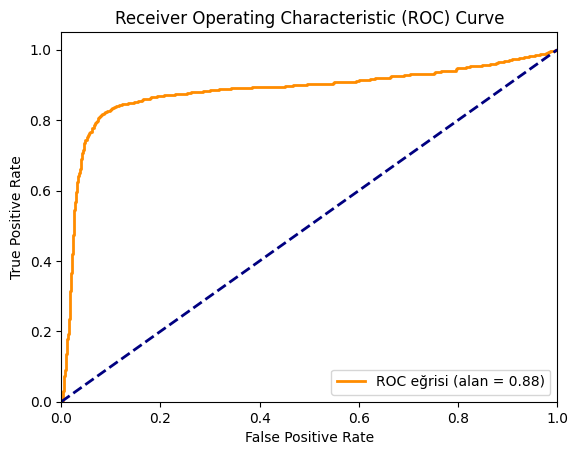

In [ ]:
# Plot ROC curve for a specific class (e.g., class 0)
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2, label='ROC eğrisi (alan = %0.2f)' % roc_auc[0])
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

Logistic Regression with GridSearch

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Hyperparameter search space
param_grid = {
    'C': [0.1, 10, 100],  # Regularizasyon parameter
    'solver': ['liblinear', 'saga'],  # Solution algorithms
    'max_iter': [5000, 10000],  # Maximum number of iterations
    'penalty': ['l2', 'l1'],  # Regularization type
}

# Logistic Regression model
log_reg = LogisticRegression(random_state=1)

# Parameter search with GridSearchCV
grid_search = GridSearchCV(estimator=log_reg, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search.fit(x_train, y_train)

# Finding the best parameters
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

# Performance on test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)
print(f"Test Set Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

# Results for K-Fold Cross Validation
mean_scores = grid_search.cv_results_['mean_test_score']
print(f"Cross-Validation Results: {mean_scores}")

# Standard deviation calculation
std_dev = np.std(mean_scores)
print(f"Standard Deviation of Cross-Validation Scores: {std_dev:.4f}")

NEURAL NETWORK

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
# Assuming X and y are already prepared and dataset was splitted into train and test set
# Define the model
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],)),  # Input layer
    keras.layers.Dense(32, activation='relu'),  # Hidden layer
    keras.layers.Dense(len(np.unique(y)), activation='softmax')  # Output layer (softmax for multi-class)
])

In [ ]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',  # Use sparse_categorical_crossentropy for integer labels
              metrics=['accuracy'])

In [ ]:
# Train the model
history = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1) # Adjust epochs and batch size as needed


In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

In [ ]:
# Make predictions
y_pred_keras = model.predict(x_test)
y_pred_classes = np.argmax(y_pred_keras, axis=1) # Get predicted class labels

In [ ]:
print(confusion_matrix(y_test, y_pred_classes))
print(classification_report(y_test, y_pred_classes))

In [ ]:
# Metrics during the training process for calculating standard deviation
history = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)

In [ ]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

In [ ]:
# Compute standard deviation for accuracy during validation
val_accuracy_list = history.history['val_accuracy']
std_dev = np.std(val_accuracy_list)  # Calculate standard deviation
print(f"Standard Deviation of Validation Accuracy: {std_dev:.3f}")

Neural Network with GridSearch

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import keras_tuner as kt

# Define the model
def build_model(hp):
    model = keras.Sequential([
        keras.layers.Dense(
            units=hp.Int('units_1', min_value=32, max_value=64, step=32),  # Reduced range
            activation='relu',
            input_shape=(x_train.shape[1],)
        ),
        keras.layers.Dense(
            units=hp.Int('units_2', min_value=16, max_value=32, step=16),  # Reduced range
            activation='relu'
        ),
        keras.layers.Dense(len(np.unique(y)), activation='softmax')  # Output layer for multi-class classification
    ])

    model.compile(
        optimizer=hp.Choice('optimizer', values=['adam', 'sgd']),  # Reduced choices
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Model search with Keras Tuner
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=30,  # Reduced epochs
    factor=3,
    directory='hyperband',
    project_name='best_model'
)

# Perform a hyperparameter search
tuner.search(x_train, y_train, epochs=30, validation_data=(x_test, y_test), batch_size=32)

# Printing best parameters and model performance
best_model = tuner.get_best_models(num_models=1)[0]
best_params = tuner.oracle.get_best_trials(num_trials=1)[0].parameters
print(f"Best Parameters: {best_params}")
print(f"Best Validation Accuracy: {tuner.oracle.get_best_trials(num_trials=1)[0].score:.3f}")

# Evaluating performance on the test set
loss, accuracy = best_model.evaluate(x_test, y_test)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

# Prediction
y_pred_keras = best_model.predict(x_test)
y_pred_classes = np.argmax(y_pred_keras, axis=1)

# Results
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_test, y_pred_classes))
print(classification_report(y_test, y_pred_classes))

# Evaluating performance on the test set
history = best_model.history

# Loss plot
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

# Accuracy plot
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

# Compute standard deviation for accuracy during validation
val_accuracy_list = history.history['val_accuracy']
std_dev = np.std(val_accuracy_list)
print(f"Standard Deviation of Validation Accuracy: {std_dev:.3f}")

Neural Network Dropout eklenmiş hali, overftting azaltmak için

In [ ]:
# Assuming X and y are already prepared and dataset was splitted into train and test set
# Define the model
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],)),  # Input layer
    keras.layers.Dropout(0.5),  # Dropout to reduce overfitting
    keras.layers.Dense(32, activation='relu'),  # Hidden layer
    keras.layers.Dropout(0.5),  # Dropout to reduce overfitting
    keras.layers.Dense(len(np.unique(y)), activation='softmax')  # Output layer (softmax for multi-class)
])

In [ ]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',  # Use sparse_categorical_crossentropy for integer labels
              metrics=['accuracy'])

In [ ]:
# Train the model
history = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")


In [ ]:
# Make predictions
y_pred_keras = model.predict(x_test)
y_pred_classes = np.argmax(y_pred_keras, axis=1)  # Get predicted class labels

In [ ]:
# Confusion matrix and classification report
print(confusion_matrix(y_test, y_pred_classes))
print(classification_report(y_test, y_pred_classes))

In [ ]:
# Calculate Standard Deviation for Validation Loss
val_loss = history.history['val_loss']
std_dev_val_loss = np.std(val_loss)
print(f"Validation Loss Standard Deviation: {std_dev_val_loss:.3f}")

In [ ]:
# Calculate Standard Deviation for Validation Accuracy
val_accuracy = history.history['val_accuracy']
std_dev_val_accuracy = np.std(val_accuracy)
print(f"Validation Accuracy Standard Deviation: {std_dev_val_accuracy:.3f}")

In [ ]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

Neural Network EarlyStopping callback eklenmiş hali

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# Assuming X and y are already prepared and dataset was splitted into train and test set
# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [ ]:
# Define the model
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],)),  # Input layer
    keras.layers.Dense(32, activation='relu'),  # Hidden layer
    keras.layers.Dense(len(np.unique(y)), activation='softmax')  # Output layer (softmax for multi-class)
])

In [ ]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',  # Use sparse_categorical_crossentropy for integer labels
              metrics=['accuracy'])

In [ ]:
# Train the model with early stopping
history = model.fit(x_train, y_train,
                    validation_split=0.1,
                    epochs=50,
                    batch_size=32,
                    callbacks=[early_stopping])  # EarlyStopping callback

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

In [ ]:
# Make predictions
y_pred_keras = model.predict(x_test)
y_pred_classes = np.argmax(y_pred_keras, axis=1)  # Get predicted class labels

In [ ]:
# Confusion matrix and classification report
print(confusion_matrix(y_test, y_pred_classes))
print(classification_report(y_test, y_pred_classes))

In [ ]:
# Calculate Standard Deviation for Validation Loss
val_loss = history.history['val_loss']
std_dev_val_loss = np.std(val_loss)
print(f"Validation Loss Standard Deviation: {std_dev_val_loss:.3f}")

In [ ]:
# Calculate Standard Deviation for Validation Accuracy
val_accuracy = history.history['val_accuracy']
std_dev_val_accuracy = np.std(val_accuracy)
print(f"Validation Accuracy Standard Deviation: {std_dev_val_accuracy:.3f}")

In [ ]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()